# Mini Lab: Why ECMP Struggles with AI Training Traffic
**Paper:** Gangidi et al., *RDMA over Ethernet for Distributed AI Training at Meta Scale* (SIGCOMM 2024)  
**Required initial reading:** **Abstract + Section 1 (Introduction)**  
**Simulation references:** **Sections 2 and 4** (especially §2.1–2.2, §4.1–4.3)  
**Total duration:** **60 minutes**  
**Environment:** Python / Google Colab (CPU only; no network equipment or GPU required)

### Learning goals
1. Explain the basic architecture and communication needs of distributed GPU training.
2. Recognize how different **collective communication patterns** affect network flows (**§2.2, Table 1**).
3. Observe how low-entropy, high-volume flows can produce uneven **ECMP** path utilization (**§4.1**).
4. Compare **QP scaling**, **Enhanced ECMP**, and an idealized **Traffic Engineering** reference (**§4.2–4.3**).


## Part 1 — Guided reading: Abstract + Introduction

Read the paper's Abstract and Section 1 (Introduction).
As you read, look for answers to these questions:

- **Why** do AI workloads require distributed training across many GPUs?
- **How** do GPUs communicate within a computing node, and what changes when communication crosses between nodes?
- **Why** did Meta choose **RDMA over Converged Ethernet (RoCE)** for its training backend?
- **What** makes the network needs of AI training different from those of a general-purpose data center?

The goal is to identify the ideas you will need to interpret the simulations.

### Part 1 answers

- **Why distributed training?** Models and data don't fit on one GPU, so training is split over many. They sync every iteration, so the network has to be fast and have steady latency.
- **Inside vs. between nodes:** Inside a server the GPUs use NVLink. Between servers it goes over the network. Meta didn't want TCP (slow, CPU heavy) or proprietary stuff (locked in).
- **Why RoCE?** Same RDMA verbs people already use, it's Ethernet so they could reuse their Clos network and tools, and it's an open standard.
- **What's different about AI traffic?** It's a few big repetitive flows that come in bursts, not lots of small varied ones. So they built a separate backend network for it.

## Part 2 — Key concepts video
Watch the short video below. It explains the key concepts from the Abstract and Introduction (with details from **§2.1–2.2** and **§4.1–4.3**) and gives an answer for each question. You will need these ideas to interpret the simulations.

### ▶ [Watch the key concepts video](https://notebook.google.com/notebook/cc839a7e-9b27-4166-aadd-11bbaf38a30a/artifact/3fb874f3-b167-490a-a7bc-e6708693587a)

**Questions the video answers:**
1. **Distributed training:** What is distributed across GPUs, and why must GPUs communicate and synchronize in every iteration?
2. **Inside vs. outside a node:** How do GPUs in the same server communicate (NVLink), and what changes between servers (RDMA NICs)?
3. **RDMA and RoCEv2:** What is RDMA, and how does RoCE carry it over Ethernet?
4. **Frontend vs. backend networks:** What runs on each, and why does Meta use a dedicated training backend?
5. **Collectives:** What are AllReduce and AlltoAll(v), and how does a Ring/Tree pattern differ from a full mesh?
6. **ECMP:** What does the five-tuple hash use? What are low flow entropy, bursty traffic and elephant flows?
7. **QPs and routing fixes:** What are QP scaling, Enhanced ECMP (E-ECMP) and Traffic Engineering (TE)?

**Keep these concepts in mind.** You will use concepts 5–6 in Experiment 1 and concept 7 in Experiment 2.

### Part 2 answers

1. **Distributed training:** The model and/or data is split over GPUs. They sync gradients every iteration, so they have to wait on each other.
2. **Inside vs. outside a node:** Same server: NVLink. Different servers: RDMA NICs and the network.
3. **RDMA and RoCEv2:** RDMA writes straight to another machine's memory, no CPU or kernel involved. RoCEv2 puts the RDMA message inside a UDP/IP/Ethernet packet.
4. **Frontend vs. backend:** Backend is a separate network just for GPU training, so it can change without touching the rest of the DC. Frontend is everything else (general background, the intro doesn't say).
5. **Collectives:** AllReduce runs as Ring or Tree, AlltoAll(v) is a full mesh. Ring/Tree have few flows, full mesh has lots but can cause incast.
6. **ECMP:** Hashes source/dest IP, source/dest UDP port and protocol. Low entropy = not many different flows. Bursty = on/off every few ms. Elephant = big flow at line rate.
7. **QPs and routing fixes:** QP scaling = send over several QPs to get more flows. E-ECMP = also hash the destination QP so they split up. TE = central controller picks the paths.

## Model assumptions (important)
This is a **small, conceptual flow-level simulation**, **not** a RoCE packet simulator or a reproduction of Meta's production measurements.

- We model **16 GPUs** and several **equal-capacity parallel paths** through an abstract network.
- **Ring** represents **one communication step** of a ring-based AllReduce, not the entire multi-step operation.
- **All-to-All** represents a **uniform full mesh** (real AlltoAllv can have unequal message sizes and incast).
- All scenarios carry the **same total amount of traffic** to make path-balance comparisons fair.
- Each distinct `(source GPU, destination GPU)` has a stable synthetic UDP 5-tuple. In our model, adding QPs does **not** change that 5-tuple. **Standard ECMP** therefore keeps the same path for all QPs of that pair.
- **Enhanced ECMP (E-ECMP)** also hashes the destination QP identifier, inspired by Meta's switch customizations. Each QP carries an equal share of its parent flow's bytes.
- **Idealized TE** greedily places whole flows on the currently least-loaded path, assuming perfect demand knowledge. It is **not** Meta's actual CSPF-based TE system.

**Metric:** `MMR = maximum link load / average link load` (Section 4.1.1). Closer to **1** means a more balanced load. Loads above the dashed line in the charts exceed one path's normalized capacity for the chosen traffic interval. **All load charts share the same y-axis**, so you can compare bar heights directly between charts and between runs.

## Setup (run once)

In [1]:
import hashlib
import numpy as np
import matplotlib.pyplot as plt

N_GPUS = 16
N_PATHS = 16
SEED = 11
# Every load chart in this notebook uses the SAME y-axis, so bar heights can be
# compared directly across charts (and across runs with N_PATHS = 8 or 16).
Y_MAX = 5.5


def traffic_matrix(pattern, n=N_GPUS):
    """Create a simplified communication matrix for one collective step."""
    m = np.zeros((n, n), dtype=float)
    if pattern == "Ring":
        for src in range(n):
            m[src, (src + 1) % n] = 1.0
    elif pattern == "All-to-All":
        m[:, :] = 1.0
        np.fill_diagonal(m, 0.0)
    else:
        raise ValueError("pattern must be 'Ring' or 'All-to-All'")
    # Keep the TOTAL traffic fixed at N_PATHS capacity-units.
    return m * (N_PATHS / m.sum())


def stable_path(*fields, n_paths=N_PATHS):
    key = "|".join(str(field) for field in fields).encode("utf8")
    return int.from_bytes(hashlib.blake2b(key, digest_size=8).digest(), "big") % n_paths


def route_traffic(matrix, mode="ECMP", qps=1, n_paths=N_PATHS, seed=SEED):
    """Return total offered traffic assigned to each equal-capacity path."""
    if mode not in {"ECMP", "E-ECMP", "Ideal TE"}:
        raise ValueError("Unknown routing mode")
    if qps < 1:
        raise ValueError("Number of QPs must be positive")
    loads = np.zeros(n_paths)
    flows = [(src, dst, matrix[src, dst])
             for src in range(matrix.shape[0])
             for dst in range(matrix.shape[1])
             if matrix[src, dst] > 0]
    if mode == "Ideal TE":
        for src, dst, amount in sorted(flows, key=lambda item: -item[2]):
            loads[np.argmin(loads)] += amount
        return loads
    for src, dst, amount in flows:
        # A fixed synthetic 5-tuple, identical across QPs for this pair.
        five_tuple = (seed, src, dst, 40000 + src, 4791, "UDP")
        for qp in range(qps):
            fields = five_tuple if mode == "ECMP" else (*five_tuple, "dst_qp", qp)
            path = stable_path(*fields, n_paths=n_paths)
            loads[path] += amount / qps
    return loads


def mmr(loads):
    return float(max(loads) / np.mean(loads))


def draw_loads(ax, loads, title):
    x = np.arange(1, len(loads) + 1)
    ax.bar(x, loads, color=plt.get_cmap("tab10")(0))
    ax.axhline(1.0, linestyle="--", linewidth=1.2, color="black", label="Path capacity")
    ax.set_xticks(x)
    ax.set_xlabel("Network path")
    ax.set_ylabel("Offered load / capacity")
    ax.set_title(f"{title}\nMMR = {mmr(loads):.2f}")
    ax.set_ylim(0, max(Y_MAX, max(loads) * 1.1))
    ax.grid(axis="y", alpha=0.2)
    ax.legend(loc="upper right", fontsize=8)

print("Setup complete.")

Setup complete.


## What are we working with? (3 min)
**The real system (paper):** Meta's training backend groups GPUs into an *AI Zone*. Each GPU has its own RDMA NIC, the NICs connect to rack switches (**RTSW**, the leaf layer), and every rack switch connects up to the cluster switches (**CTSW**, the spine layer) in a two-stage Clos. Traffic leaving a rack can go up through any spine, so the leaf switch must choose among several **equal-cost paths**. That choice is the ECMP decision this lab studies.

**Our simplified model** keeps only the part that matters for load balancing:
- **16 GPUs** that send and receive. They are drawn twice: senders on the left, receivers on the right.
- One switch on each side stands in for the leaf layer. The **source switch** hashes each flow onto one path.
- **`N_PATHS` equal-capacity paths** (8 by default) stand in for the spine uplinks. Each path has capacity **1.0**.
- Each collective step offers exactly **`N_PATHS` units** of traffic in total, so a perfectly balanced network puts **1.0** on every path.
- NVLink inside a server is ignored: every flow in the model crosses the network.

**Run the cell below.** The highlighted line follows one Ring flow through the network.

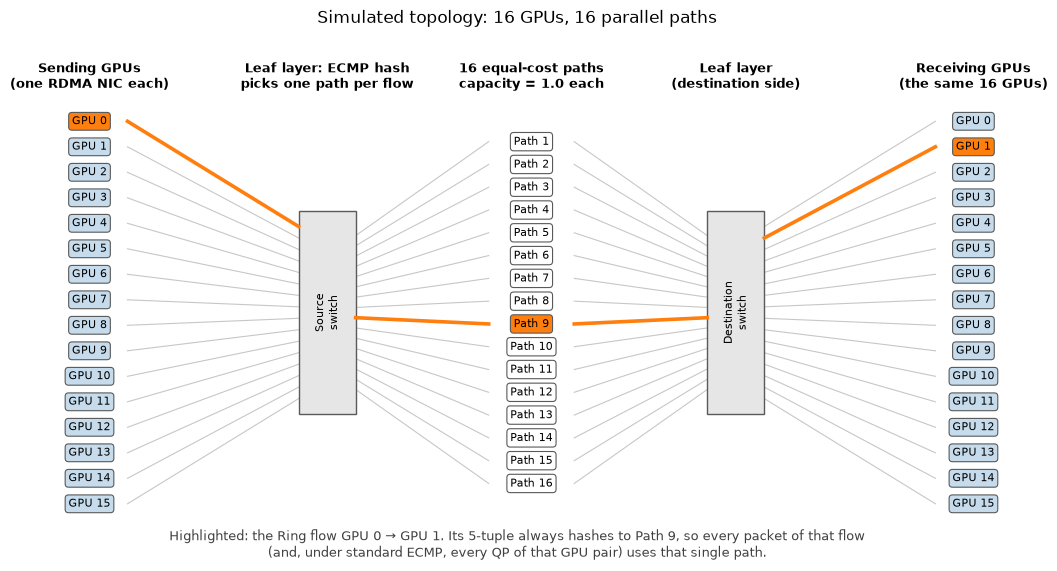

Ring      :  16 flows × 1.000 capacity units each = 16.0 units in total
All-to-All: 240 flows × 0.067 capacity units each = 16.0 units in total
Perfect balance: exactly 1.0 unit on each of the 16 paths (MMR = 1.00).


In [2]:
def draw_topology(n_gpus=N_GPUS, n_paths=N_PATHS, example=(0, 1)):
    """Sketch the abstract network that the experiments route traffic over."""
    fig, ax = plt.subplots(figsize=(13, 6.5))
    ax.set_xlim(-0.3, 10.3)
    ax.set_ylim(-0.1, 1.13)
    ax.axis("off")

    gpu_y = np.linspace(0.97, 0.03, n_gpus)
    path_y = np.linspace(0.92, 0.08, n_paths)
    x_src, x_sw1, x_path, x_sw2, x_dst = 0.5, 3.0, 5.15, 7.3, 9.8
    grey, accent = "0.78", plt.get_cmap("tab10")(1)

    # The same synthetic 5-tuple that route_traffic() hashes for this flow.
    src, dst = example
    chosen = stable_path(SEED, src, dst, 40000 + src, 4791, "UDP", n_paths=n_paths)

    def edge_y(y):
        # Spread links along the switch's edge instead of meeting at one point.
        return 0.5 + (y - 0.5) * 0.45

    def link(x0, y0, x1, y1, highlight=False):
        ax.plot([x0, x1], [y0, y1], color=accent if highlight else grey,
                lw=2.6 if highlight else 0.8, zorder=5 if highlight else 1)

    for i, y in enumerate(gpu_y):
        link(x_src + 0.4, y, x_sw1 - 0.3, edge_y(y), highlight=(i == src))
        link(x_sw2 + 0.3, edge_y(y), x_dst - 0.4, y, highlight=(i == dst))
    for k, y in enumerate(path_y):
        link(x_sw1 + 0.3, edge_y(y), x_path - 0.45, y, highlight=(k == chosen))
        link(x_path + 0.45, y, x_sw2 - 0.3, edge_y(y), highlight=(k == chosen))

    def box(x, y, label, color):
        ax.text(x, y, label, ha="center", va="center", fontsize=8, zorder=6,
                bbox=dict(boxstyle="round,pad=0.3", fc=color, ec="0.35", lw=0.8))

    gpu_color = plt.get_cmap("tab10")(0, alpha=0.25)
    for i, y in enumerate(gpu_y):
        box(x_src, y, f"GPU {i}", accent if i == src else gpu_color)
        box(x_dst, y, f"GPU {i}", accent if i == dst else gpu_color)
    for k, y in enumerate(path_y):
        box(x_path, y, f"Path {k + 1}", accent if k == chosen else "white")
    for x, label in [(x_sw1, "Source\nswitch"), (x_sw2, "Destination\nswitch")]:
        ax.add_patch(plt.Rectangle((x - 0.3, 0.25), 0.6, 0.5, fc="0.9", ec="0.35", zorder=4))
        ax.text(x, 0.5, label, ha="center", va="center", fontsize=8, rotation=90, zorder=6)

    headers = [(x_src, "Sending GPUs\n(one RDMA NIC each)"),
               (x_sw1, "Leaf layer: ECMP hash\npicks one path per flow"),
               (x_path, f"{n_paths} equal-cost paths\ncapacity = 1.0 each"),
               (x_sw2, "Leaf layer\n(destination side)"),
               (x_dst, f"Receiving GPUs\n(the same {n_gpus} GPUs)")]
    for x, text in headers:
        ax.text(x, 1.08, text, ha="center", va="center", fontsize=9, fontweight="bold")

    ax.text(5.0, -0.07,
            f"Highlighted: the Ring flow GPU {src} → GPU {dst}. Its 5-tuple always hashes to "
            f"Path {chosen + 1}, so every packet of that flow\n(and, under standard ECMP, every QP "
            f"of that GPU pair) uses that single path.",
            ha="center", va="center", fontsize=9, color="0.25")
    ax.set_title(f"Simulated topology: {n_gpus} GPUs, {n_paths} parallel paths", fontsize=12, pad=24)


draw_topology()
plt.show()

for name in ["Ring", "All-to-All"]:
    m = traffic_matrix(name)
    print(f"{name:10s}: {np.count_nonzero(m):3d} flows × {m.max():.3f} capacity units each "
          f"= {m.sum():.1f} units in total")
print(f"Perfect balance: exactly {traffic_matrix('Ring').sum() / N_PATHS:.1f} unit on each of "
      f"the {N_PATHS} paths (MMR = 1.00).")

## Experiment 1 — Why does the collective matter? (8 min)
**Paper connection:** Section 2.2 and Table 1 describe how different collectives produce different communication patterns. Meta notes that sparse Ring/Tree traffic tends to have lower flow entropy, while full-mesh AlltoAll(v) has more flows but can cause incast.

**Run the following cell.** It displays (a) who communicates with whom and (b) the resulting ECMP path loads, with **the same total traffic volume** in both cases.

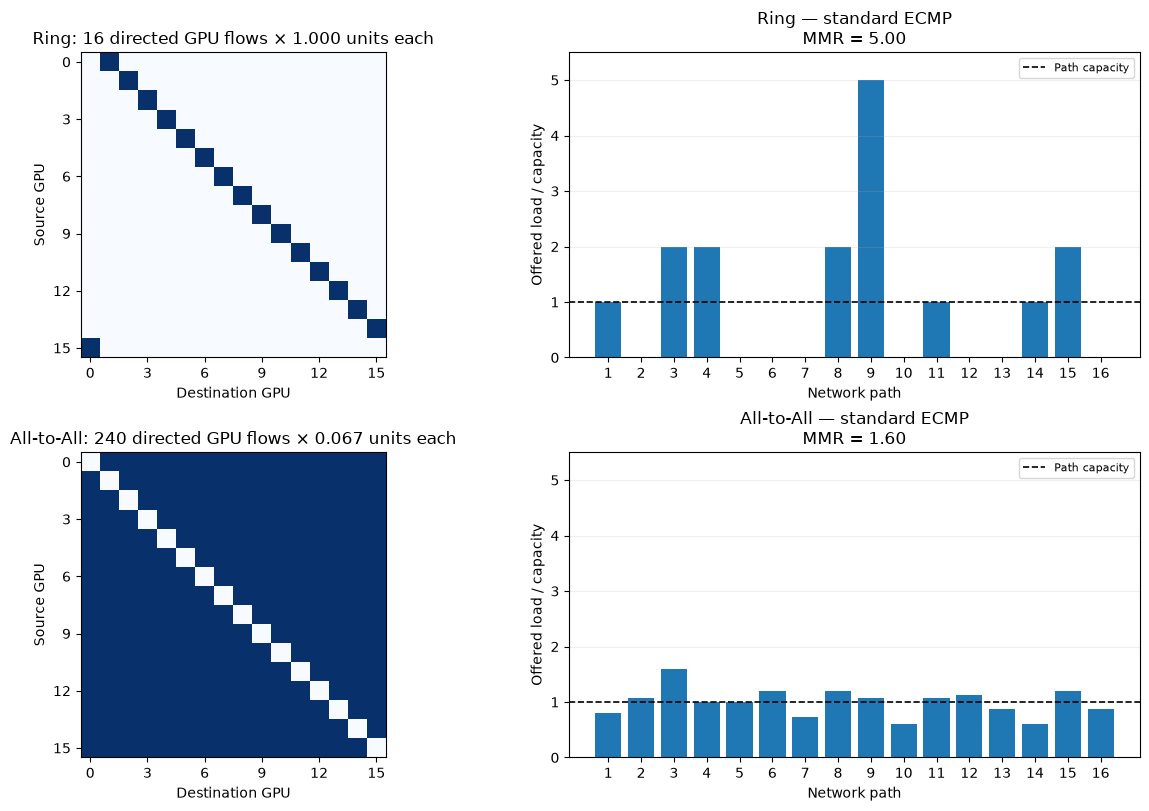

In [3]:
patterns = ["Ring", "All-to-All"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for row, name in enumerate(patterns):
    matrix = traffic_matrix(name)
    axes[row, 0].imshow(matrix > 0, cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
    axes[row, 0].set_title(f"{name}: {np.count_nonzero(matrix)} directed GPU flows "
                           f"× {matrix.max():.3f} units each")
    axes[row, 0].set_xlabel("Destination GPU")
    axes[row, 0].set_ylabel("Source GPU")
    axes[row, 0].set_xticks(range(0, N_GPUS, 3))
    axes[row, 0].set_yticks(range(0, N_GPUS, 3))
    loads = route_traffic(matrix, mode="ECMP", qps=1)
    draw_loads(axes[row, 1], loads, f"{name} — standard ECMP")
plt.show()

**Task 1 (write 1–2 sentences):** Which pattern has fewer flows, and which produces a more uneven ECMP load in **your run**? Explain why the result is plausible based on **Section 2.2**.

**Answer:**

> Ring has fewer flows (16 vs 240) and is more uneven (MMR 3.00 vs 1.33 with 8 paths, 5.00 vs 1.60 with 16). Section 2.2 says Ring is sparse, so there are only a few flows to hash and they collide. All-to-All has lots of flows so it evens out.

## Experiment 2 — Does adding QPs fix ECMP? (14 min)
**Paper connection:** In **Section 4.2**, Meta explains why simply creating more QPs does not necessarily increase the entropy seen by a traditional 5-tuple hash. It enhanced hashing to include the **destination QP** field. **Section 4.3** describes a separate route: centralized Traffic Engineering (TE), which uses topology and traffic information.

For the low-entropy **Ring** case, run the following comparison:

- **ECMP, 1 QP**: baseline.
- **ECMP, 16 QPs**: additional QPs, but **not** visible to the synthetic 5-tuple hash.
- **E-ECMP, 4 QPs**: switch hash includes QP ID.
- **E-ECMP, 16 QPs**: more hash diversity.
- **Idealized TE**: a *conceptual upper-bound reference* based on perfect knowledge of offered loads.

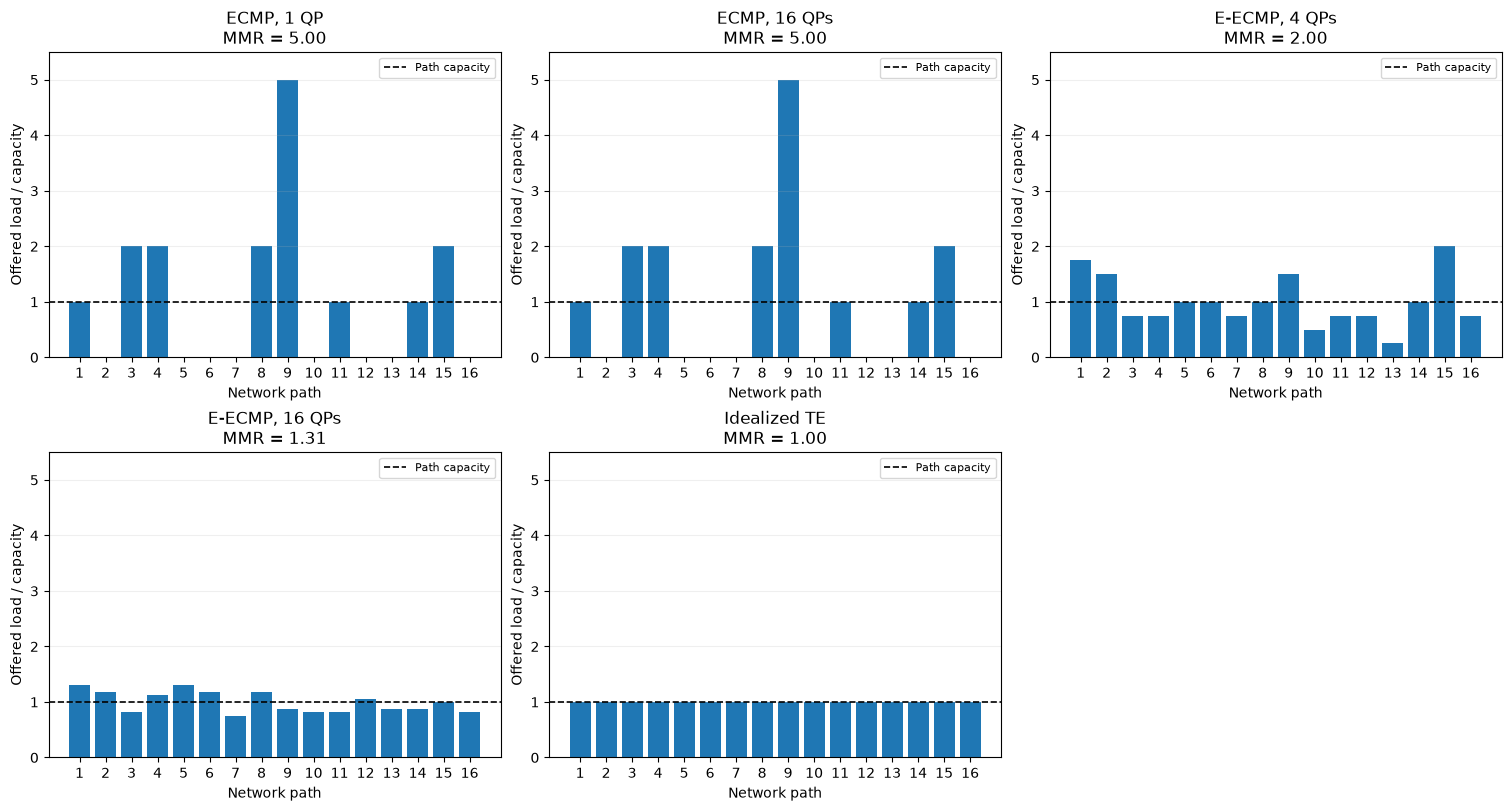

Summary (smaller MMR and smaller maximum load are better):
ECMP, 1 QP           MMR: 5.00   Maximum path load: 5.00
ECMP, 16 QPs         MMR: 5.00   Maximum path load: 5.00
E-ECMP, 4 QPs        MMR: 2.00   Maximum path load: 2.00
E-ECMP, 16 QPs       MMR: 1.31   Maximum path load: 1.31
Idealized TE         MMR: 1.00   Maximum path load: 1.00


In [4]:
ring = traffic_matrix("Ring")
scenarios = [
    ("ECMP, 1 QP", "ECMP", 1),
    ("ECMP, 16 QPs", "ECMP", 16),
    ("E-ECMP, 4 QPs", "E-ECMP", 4),
    ("E-ECMP, 16 QPs", "E-ECMP", 16),
    ("Idealized TE", "Ideal TE", 1),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for ax, (label, mode, qps) in zip(axes.flat, scenarios):
    loads = route_traffic(ring, mode=mode, qps=qps)
    draw_loads(ax, loads, label)
for ax in axes.flat[len(scenarios):]:
    ax.axis("off")
plt.show()
print("Summary (smaller MMR and smaller maximum load are better):")
for label, mode, qps in scenarios:
    loads = route_traffic(ring, mode=mode, qps=qps)
    print(f"{label:19s}  MMR: {mmr(loads):.2f}   Maximum path load: {loads.max():.2f}")

**Now change ONE parameter and rerun:** In the **Setup** cell, change `N_PATHS = 8` to `N_PATHS = 16`, then rerun all code cells. If you use Colab, select **Runtime → Run all**. Compare the new MMR values with the previous run. (You can restore `N_PATHS = 8` afterward.)

**Task 2:** Does ECMP with 16 QPs improve over ECMP with 1 QP in **this model**? Why or why not? Relate your answer to **Section 4.2.1–4.2.2**.

**Answer:**

> No, same result as 1 QP (MMR 3.00 with 8 paths, 5.00 with 16). More QPs don't change the 5-tuple, so they all hash to the same path. The paper says the same in 4.2.1. E-ECMP (4.2.2) also hashes the destination QP, and that drops MMR to 1.09 (8 paths) or 1.31 (16 paths).

**Task 3:** Does E-ECMP with 16 QPs always achieve the idealized TE result? What trade-off does Meta identify for additional QPs, and what trade-off does it identify for TE? See **Sections 4.2.3 and 4.4.3**.

**Answer:**

> No. It gets 1.09 vs 1.00 for TE with 8 paths, and 1.31 vs 1.00 with 16, since hashing is still random. More QPs use up limited NIC buffer space (4.2.3). TE needs a central controller, which is more complex, and it handles multiple link failures badly (4.4.3).

**Task 4:** After changing the number of paths, how does the Ring workload's MMR change? Explain why a larger number of available paths does **not automatically** eliminate collisions when the number of elephant flows remains small.

**Answer:**

> It gets worse: ECMP goes from 3.00 to 5.00. There are still only 16 flows, and with 16 paths each one is a full path's worth of traffic, so any collision overloads a path. Random hashing almost never puts 16 flows on 16 different paths. More paths only help if there are many more flows than paths.

## Submit (6 min)
Submit **this notebook** with the generated plots, your parameter change, and **four brief answers** (Tasks 1–4). No additional report is needed.

**What to remember:** Meta's core insight is **workload-aware design**: the collective communication pattern affects flow entropy, which affects routing effectiveness. Increasing QPs can help **only when the network hashes on fields that distinguish them**. E-ECMP and TE each improve load balance, but have different resource and operational costs.

*Source: Gangidi et al., “RDMA over Ethernet for Distributed AI Training at Meta Scale,” ACM SIGCOMM 2024, Sections 2 and 4. This teaching simulation uses invented traffic volumes and simplified route assignment; its outputs are not the paper's empirical results.*